# Componente 1 — Línea base (v2, sobre `data/oro_v2`)

**Ventana:** 2026-01-01 a 2026-08-31 (ocho meses). Septiembre (23 viajes) queda fuera; julio (6,887 viajes vs ~9,000) se marca como posible hueco de extracción.
**Métrica:** utilización de la flota en toneladas (uᵢ = qᵢ / cᵢ, con capacidad legal NOM-012-SCT-2), y su traducción a costo por tonelada.

## 1. Carga de datos y ventana

In [1]:
# Rutas: el notebook vive en analisis_estadistico_IA/, pero data/, config/ y resultados_ternium/ están en la raíz.
# Se trabaja desde la raíz y se agregan las carpetas de código al path para importar sus módulos.
import os, sys
from pathlib import Path
RAIZ = Path.cwd().parent if Path.cwd().name == 'analisis_estadistico_IA' else Path.cwd()
os.chdir(RAIZ)
for _carpeta in ('analisis_estadistico_IA', 'data_processing'):
    if str(RAIZ / _carpeta) not in sys.path:
        sys.path.insert(0, str(RAIZ / _carpeta))

# Propósito: Cargar la capa oro v2 y quedarse solo con los viajes de la ventana de análisis (ene–ago 2026).
import pandas as pd, numpy as np, matplotlib, matplotlib.pyplot as plt, seaborn as sns
from pathlib import Path

ORO = Path('data/oro_v2/viajes_foraneos_oro.csv')
df_raw = pd.read_csv(ORO, low_memory=False, parse_dates=['FECHA_EGRESO'])
VENTANA = ('2026-01-01', '2026-09-01')   # [inicio, fin): ene–ago 2026; sept (23 viajes) fuera
df_raw = df_raw[(df_raw['FECHA_EGRESO'] >= VENTANA[0]) & (df_raw['FECHA_EGRESO'] < VENTANA[1])].copy()
print(f'Viajes en ventana: {len(df_raw):,}')

Viajes en ventana: 71,944


In [2]:
# Estilo común de las figuras del reporte. Regla: solo se grafica lo que lleva intervalo de confianza;
# lo descriptivo (conteos, mezclas) va en tabla.
# Paleta categórica validada (orden fijo, segura para daltonismo en pares adyacentes; ver skill dataviz).
# Tres colores (aqua, amarillo, magenta) tienen contraste < 3:1 con el fondo → siempre van con etiqueta o tabla.
import matplotlib.ticker as mtick
from matplotlib.patches import Patch

SUPERFICIE, TINTA, TINTA_2, TINTA_3, REJILLA = '#fcfcfb', '#0b0b0b', '#52514e', '#8a8984', '#e4e3df'
COLOR_UNIDAD = {                       # el color sigue a la unidad en TODAS las figuras
    'Torton':           '#2a78d6',     # azul
    '2 Ejes':           '#eb6834',     # naranja
    'Caja Seca 2 Ejes': '#1baf7a',     # aqua
    '3 Ejes':           '#eda100',     # amarillo
    'Big Coil':         '#e87ba4',     # magenta
    'Full':             '#008300',     # verde
}
COLOR_EXCLUIDO = '#c9c8c2'
SECUENCIAL = ['#cde2fb', '#9ec5f4', '#6da7ec', '#3987e5', '#256abf', '#184f95', '#0d366b']   # azul claro→oscuro

plt.rcParams.update({
    'figure.facecolor': SUPERFICIE, 'axes.facecolor': SUPERFICIE, 'savefig.facecolor': SUPERFICIE,
    'axes.edgecolor': REJILLA, 'axes.labelcolor': TINTA_2, 'axes.titlecolor': TINTA,
    'axes.spines.top': False, 'axes.spines.right': False,
    'axes.grid': True, 'grid.color': REJILLA, 'grid.linewidth': 0.8,
    'xtick.color': TINTA_2, 'ytick.color': TINTA_2, 'text.color': TINTA,
    'font.size': 10.5, 'axes.titlesize': 12, 'axes.titleweight': 'bold', 'axes.titlelocation': 'center',
    'legend.frameon': False, 'figure.dpi': 110,
})

def titulo(fig, texto, subtitulo=None):
    """Título centrado y, si hace falta, un subtítulo corto. Acomoda la figura debajo (llamar al final)."""
    h = fig.get_figheight()
    fig.suptitle(texto, x=0.5, y=1 - 0.12 / h, va='top', ha='center', fontweight='bold', fontsize=13.5)
    if subtitulo:
        fig.text(0.5, 1 - 0.45 / h, subtitulo, ha='center', va='top', color=TINTA_2, fontsize=10)
    fig.tight_layout(rect=(0, 0, 1, 1 - (0.8 if subtitulo else 0.5) / h))

def leyenda_unidades(ax, unidades, **kw):
    ax.legend(handles=[Patch(color=COLOR_UNIDAD[u], label=u) for u in unidades], **kw)

FUENTE = 'Fuente: viajes foráneos Ternium, egresos ene–ago 2026 (oro v2).'

## 2. Universo de análisis

Se incluyen las plataformas de 2 y 3 ejes, las Big Coil, los Full, la caja seca de 2 ejes y los Torton (unidades cerradas: pueden mover otro tipo de carga si resulta rentable). Se excluyen las Cortina de 3 ejes y las Portacintas comunes (indicación de Ternium) y las unidades fuera de alcance (camionetas, Heavy, cama baja, Tortoneta, plataformas largas). La tabla deja trazado cada viaje excluido y su motivo.

In [3]:
# Propósito: Definir el universo de análisis. Cada familia de camión se mapea a una de las 6 unidades del
# estudio o a un motivo de exclusión; la tabla de trazabilidad deja registrado cada viaje excluido.
FAM = 'FAMILIA_CAMION_DESC'
MAPA_UNIDAD = {
    'TORTON':                                   'Torton',
    'CAJA SECA 2 EJES NEUMATICA':               'Caja Seca 2 Ejes',
    'PLATAFORMA 2 EJES NEUMATICA':              '2 Ejes',
    'PLATAFORMA 2 EJES MUELLES':                '2 Ejes',
    'PLATAFORMA 2 EJES NEUMATICA DESACOPLADA':  '2 Ejes',
    'PLATAFORMA 3 EJES NEUMATICA':              '3 Ejes',
    'PLATAFORMA 3 EJES MUELLES':                '3 Ejes',
    'PLATAFORMA 3 EJES NEUMATICA CORTA':        '3 Ejes',
    'PLATAFORMA 3 EJES NEUMATICA CORTA LIGERA': '3 Ejes',
    'PLATAFORMA 3 EJES NEUMATICA ULTRA LIGERA': '3 Ejes',
    'PLATAFORMA 3 EJES NEUMATICA BIG COIL':     'Big Coil',
    'FULL NEUMATICA':                           'Full',
}
MOTIVO_EXCLUSION = {
    'PLATAFORMA 3 EJES NEUMATICA CORTINA':           'Cortina 3 ejes (indicación de Ternium)',
    'PLATAFORMA 2 EJES NEUMATICA CORTINA':           'Cortina (consistencia con 3 ejes)',
    'PLATAFORMA 3 EJES NEUMATICA BASES PORTACINTAS': 'Portacintas común (indicación de Ternium)',
    'CAMIONETA 35':                                  'Unidad ligera (fuera de alcance)',
    'HEAVY':                                         'Unidad especial (fuera de alcance)',
    'CAMA BAJA DOBLE PISO':                          'Unidad especial (fuera de alcance)',
    'TORTONETA':                                     'Camión rígido sin tara NOM confirmada',
    'PLATAFORMA LARGA 48 PIES':                      'Plataforma larga sin mapeo NOM',
    'PLATAFORMA LARGA 53 PIES':                      'Plataforma larga sin mapeo NOM',
}
df_raw['Unidad'] = df_raw[FAM].map(MAPA_UNIDAD)
df_raw['Motivo_Exclusion'] = df_raw[FAM].map(MOTIVO_EXCLUSION)
# 5 viajes sin familia: el respaldo 'Tipo Camión' dice Plataforma larga 40 pies
sin_fam = df_raw[FAM].isna()
df_raw.loc[sin_fam, 'Motivo_Exclusion'] = 'Plataforma larga 40 pies (sin familia, sin capacidad)'
sin_regla = df_raw.loc[df_raw['Unidad'].isna() & df_raw['Motivo_Exclusion'].isna(), FAM].unique()

assert len(sin_regla) == 0, f'Familias sin regla: {sin_regla}'

# Tabla de trazabilidad para el reporte
traz = (df_raw.assign(Estado=np.where(df_raw['Unidad'].notna(), 'Incluido', 'Excluido'))
        .groupby(['Estado', FAM], dropna=False)
        .agg(Viajes=('ID_VIAJE', 'size'), Toneladas=('Toneladas_Reales', 'sum'),
             Unidad=('Unidad', 'first'), Motivo=('Motivo_Exclusion', 'first'))
        .sort_values(['Estado', 'Viajes'], ascending=[False, False]))
traz['% viajes'] = (traz['Viajes'] / len(df_raw) * 100).round(1)
traz['Unidad / motivo'] = traz['Unidad'].fillna(traz['Motivo'])
display(traz[['Viajes', '% viajes', 'Unidad / motivo']])

# Universo: solo viajes con unidad asignada. La unidad se ordena de menor a mayor capacidad.
df = df_raw[df_raw['Unidad'].notna()].copy()
UNIDADES = ['Torton', '2 Ejes', 'Caja Seca 2 Ejes', '3 Ejes', 'Big Coil', 'Full']
df['Unidad'] = pd.Categorical(df['Unidad'], UNIDADES, ordered=True)
print(f"\nUniverso: {len(df):,} viajes ({len(df)/len(df_raw):.1%}) y "
      f"{df['Toneladas_Reales'].sum()/1e3:,.0f} mil t ({df['Toneladas_Reales'].sum()/df_raw['Toneladas_Reales'].sum():.1%})")

Viajes  % viajes  \
Estado   FAMILIA_CAMION_DESC                                               
Incluido PLATAFORMA 3 EJES NEUMATICA                     36552      50.8   
         PLATAFORMA 2 EJES NEUMATICA                     13659      19.0   
         PLATAFORMA 3 EJES NEUMATICA BIG COIL             3872       5.4   
         TORTON                                           2080       2.9   
         FULL NEUMATICA                                    729       1.0   
         PLATAFORMA 3 EJES NEUMATICA ULTRA LIGERA          481       0.7   
         PLATAFORMA 3 EJES NEUMATICA CORTA LIGERA          468       0.7   
         CAJA SECA 2 EJES NEUMATICA                        285       0.4   
         PLATAFORMA 3 EJES NEUMATICA CORTA                 123       0.2   
         PLATAFORMA 3 EJES MUELLES                          23       0.0   
         PLATAFORMA 2 EJES MUELLES                           2       0.0   
         PLATAFORMA 2 EJES NEUMATICA DESACOPLADA             1       0.0   
Excluido PLATAFORMA 3 EJES NEUMATICA CORTINA              9390      13.1   
         PLATAFORMA 3 EJES NEUMATICA BASES PORTACINTAS    2370       3.3   
         CAMIONETA 35                                      624       0.9   
         PLATAFORMA LARGA 48 PIES                          420       0.6   
         HEAVY                                             362       0.5   
         TORTONETA                                         283       0.4   
         CAMA BAJA DOBLE PISO                              170       0.2   
         PLATAFORMA LARGA 53 PIES                           37       0.1   
         PLATAFORMA 2 EJES NEUMATICA CORTINA                 8       0.0   
         NaN                                                 5       0.0   

                                                                                          Unidad / motivo  
Estado   FAMILIA_CAMION_DESC                                                                               
Incluido PLATAFORMA 3 EJES NEUMATICA                                                               3 Ejes  
         PLATAFORMA 2 EJES NEUMATICA                                                               2 Ejes  
         PLATAFORMA 3 EJES NEUMATICA BIG COIL                                                    Big Coil  
         TORTON                                                                                    Torton  
         FULL NEUMATICA                                                                              Full  
         PLATAFORMA 3 EJES NEUMATICA ULTRA LIGERA                                                  3 Ejes  
         PLATAFORMA 3 EJES NEUMATICA CORTA LIGERA                                                  3 Ejes  
         CAJA SECA 2 EJES NEUMATICA                                                      Caja Seca 2 Ejes  
         PLATAFORMA 3 EJES NEUMATICA CORTA                                                         3 Ejes  
         PLATAFORMA 3 EJES MUELLES                                                                 3 Ejes  
         PLATAFORMA 2 EJES MUELLES                                                                 2 Ejes  
         PLATAFORMA 2 EJES NEUMATICA DESACOPLADA                                                   2 Ejes  
Excluido PLATAFORMA 3 EJES NEUMATICA CORTINA                       Cortina 3 ejes (indicación de Ternium)  
         PLATAFORMA 3 EJES NEUMATICA BASES PORTACINTAS          Portacintas común (indicación de Ternium)  
         CAMIONETA 35                                                    Unidad ligera (fuera de alcance)  
         PLATAFORMA LARGA 48 PIES                                          Plataforma larga sin mapeo NOM  
         HEAVY                                                         Unidad especial (fuera de alcance)  
         TORTONETA                                                  Camión rígido sin tara NOM confirmada  
         CAMA BAJA DOBLE PISO                                          


Universo: 58,275 viajes (81.0%) y 1,671 mil t (81.3%)


## 3. Distribución de unidades por planta de origen

In [4]:
# Propósito: Tabla de mezcla de unidades por planta de origen (viajes y % de la planta). Plantas con ≥ 30 viajes.
GRUPO, PLANTA = 'GRUPO_PLANTA_ORIGEN', 'PLANTA_ORIGEN'
orden_plantas = (df.groupby([GRUPO, PLANTA]).size().reset_index(name='n')
                   .sort_values([GRUPO, 'n'], ascending=[True, False]))
orden_plantas = orden_plantas[orden_plantas['n'] >= 30]           # plantas marginales aparte
idx = pd.MultiIndex.from_frame(orden_plantas[[GRUPO, PLANTA]])

# Viajes, toneladas (miles) y % de cada unidad dentro de su planta
viajes = pd.crosstab([df[GRUPO], df[PLANTA]], df['Unidad']).reindex(idx)
ton    = df.pivot_table(index=[GRUPO, PLANTA], columns='Unidad', values='Toneladas_Reales',
                        aggfunc='sum', observed=False).reindex(idx) / 1e3
mezcla = viajes.div(viajes.sum(axis=1), axis=0) * 100

# Tabla única: en cada celda, viajes de esa unidad en la planta y (entre paréntesis) qué % de los viajes
# de la planta representan. Cada renglón suma 100 %. Celdas vacías = la planta no usa esa unidad.
tabla = pd.DataFrame(index=idx)
for u in UNIDADES:
    tabla[u] = [f'{n:,} ({pct:.0f}%)' if n > 0 else '' for n, pct in zip(viajes[u], mezcla[u])]
tabla['Total viajes'] = viajes.sum(axis=1).map('{:,}'.format)
tabla['t por viaje'] = (ton.sum(axis=1) * 1e3 / viajes.sum(axis=1)).round(1)
tabla.index.names = ['Grupo', 'Planta']
print('Viajes por unidad y planta de origen — n (% de los viajes de la planta), ene–ago 2026')
display(tabla)

marginales = df.groupby(PLANTA).size().loc[lambda s: s < 30]
print('Plantas marginales (<30 viajes, fuera de la tabla):', marginales.to_dict())


Viajes por unidad y planta de origen — n (% de los viajes de la planta), ene–ago 2026


Torton       2 Ejes Caja Seca 2 Ejes  \
Grupo      Planta                                                         
Bodega     Bodega del Toro                   158 (45%)                    
           Bodega Aceromex                    15 (20%)                    
CEDIS      CEDI Mexico           129 (7%)  1,641 (90%)                    
           CEDI Veracruz        769 (92%)      60 (7%)                    
           CEDI Tuxtla          636 (76%)      31 (4%)                    
           CEDI Puebla          278 (70%)    105 (26%)                    
           CEDI Norte            52 (16%)     83 (25%)                    
           CEDI Guadalajara     216 (92%)      20 (8%)                    
CeSer      CSI Apodaca                         83 (7%)                    
           CSI San Luis Potosi               582 (60%)                    
Largos     Largos Puebla                        1 (0%)                    
           Largos Apodaca                  3,382 (44%)                    
Masivos    Pesquería                       2,256 (17%)                    
           Churubusco                        926 (14%)                    
           Guerrero                        1,548 (23%)                    
Revestidos Juventud                        2,191 (32%)         285 (4%)   
           Universidad                       579 (39%)                    

                                     3 Ejes     Big Coil      Full  \
Grupo      Planta                                                    
Bodega     Bodega del Toro        184 (52%)      13 (4%)             
           Bodega Aceromex         60 (80%)                          
CEDIS      CEDI Mexico              61 (3%)                          
           CEDI Veracruz             8 (1%)                          
           CEDI Tuxtla            168 (20%)                          
           CEDI Puebla              14 (4%)                          
           CEDI Norte             193 (59%)                          
           CEDI Guadalajara                                          
CeSer      CSI Apodaca          1,087 (93%)                          
           CSI San Luis Potosi    386 (40%)                          
Largos     Largos Puebla        7,779 (91%)               729 (9%)   
           Largos Apodaca       4,306 (56%)                          
Masivos    Pesquería            7,465 (56%)  3,541 (27%)             
           Churubusco           5,513 (82%)     294 (4%)             
           Guerrero             5,109 (76%)      24 (0%)             
Revestidos Juventud             4,395 (64%)                          
           Universidad            918 (61%)                          

                               Total viajes  t por viaje  
Grupo      Planta                                         
Bodega     Bodega del Toro              355         27.3  
           Bodega Aceromex               75         30.1  
CEDIS      CEDI Mexico                1,831         22.1  
           CEDI Veracruz                837         16.1  
           CEDI Tuxtla                  835         18.5  
           CEDI Puebla                  397         18.9  
           CEDI Norte                   328         21.3  
           CEDI Guadalajara             236         14.5  
CeSer      CSI Apodaca                1,170         29.5  
           CSI San Luis Potosi          968         27.5  
Largos     Largos Puebla              8,509         35.8  
           Largos Apodaca             7,688         29.1  
Masivos    Pesquería                 13,262         28.5  
           Churubusco                 6,733         28.9  
           Guerrero                   6,681         29.6  
Revestidos Juventud                   6,871         24.6  
           Universidad                1,497         29.1

Plantas marginales (<30 viajes, fuera de la tabla): {'Bodega Foremex Agua Fria': 1, 'CSC Apodaca': 1}


## 4. Capacidad legal y utilización de la flota

**Capacidad (carga útil legal)** = peso bruto vehicular de la NOM-012-SCT-2 (camino ET y A) − tara. El PBV coincide con la suma de los límites por eje (Tabla A-2). Ternium reporta taras de 14–17 t para tractocamión con remolque. Dentro de ese rango asignamos **una tara por unidad**, coherente con el orden físico de los remolques y con el supuesto de que Ternium casi nunca excede el límite legal (≤ 1 % de viajes; si lo hace, con permiso especial). Es un supuesto provisional que se reemplaza con los datos exactos de Ternium; la banda [14, 17] t queda como sensibilidad. El **Torton** no tiene tara confirmada, así que su capacidad es su techo operativo (P99 observado); es un supuesto declarado.

**Utilización** del viaje *i*: uᵢ = qᵢ / cᵢ. Solo se mide el peso, y la utilización real es el máximo sobre todas las dimensiones (peso, volumen, largo), así que **u en peso es una cota inferior** y la capacidad ociosa es una cota superior.

### 4.1 Capacidades por unidad y viajes por encima del límite legal

In [5]:
# Carga útil legal = PBV (NOM-012-SCT-2, camino ET y A; coincide con la suma de límites por eje, Tabla A-2) − tara.
#
# TARA POR UNIDAD (supuesto provisional, se reemplaza cuando Ternium entregue los datos exactos):
#   Ternium reporta 14–17 t para tractocamión + remolque. Dentro de ese rango asignamos a cada unidad una tara
#   coherente con dos criterios:
#   (1) Orden físico: plataforma 2 ejes < plataforma 3 ejes < 3 ejes Big Coil (cuna reforzada);
#       caja seca 2 ejes > plataforma 2 ejes (unidad cerrada).
#   (2) Cumplimiento: suponemos que Ternium casi nunca excede el límite legal (y que, si lo hace, es con
#       permiso especial). La tara elegida debe dejar ≤ 1 % de viajes por encima de la carga útil.
#   Full (T3-S2-R4): por su configuración (dos remolques + dolly) su tara física debería ser mayor, pero con más
#   de 15.5 t uno de cada cinco Full excedería el límite. Bajo el supuesto (2) usamos 15.5 t y lo marcamos pendiente.
#   Torton: sin tara confirmada → capacidad = techo operativo (P99 observado).
# Sensibilidad: banda de Ternium [14, 17] t para todas las unidades con tara.
TARA_T = pd.Series({'2 Ejes': 14.5, 'Caja Seca 2 Ejes': 16.0, '3 Ejes': 15.5,
                    'Big Coil': 16.5, 'Full': 15.5, 'Torton': np.nan})
TARA_BANDA = {'baja': 14.0, 'alta': 17.0}

cap = pd.DataFrame({
    'Config_NOM': ['C3 (10 llantas)', 'T3-S2', 'T3-S2', 'T3-S3', 'T3-S3', 'T3-S2-R4'],
    'PBV_t':      [27.5, 46.5, 46.5, 54.0, 54.0, 66.5],
    'Fuente_cap': ['techo operativo P99'] + ['NOM-012 − tara'] * 5,
}, index=pd.Index(UNIDADES, name='Unidad'))
cap['Tara_t'] = TARA_T.reindex(cap.index)
cap['Cap_central_t'] = cap['PBV_t'] - cap['Tara_t']
for k, tara in TARA_BANDA.items():
    cap[f'Cap_{k}_t'] = cap['PBV_t'] - tara             # 'baja' = tara 14 → más capacidad
cap['Techo_P99_t'] = df.groupby('Unidad', observed=True)['Toneladas_Reales'].quantile(.99)
cap.loc['Torton', ['Cap_central_t', 'Cap_baja_t', 'Cap_alta_t']] = cap.loc['Torton', 'Techo_P99_t']

for k in ['central', 'baja', 'alta']:
    df[f'Cap_{k}_t'] = df['Unidad'].map(cap[f'Cap_{k}_t']).astype(float)
cap['% excede (tara elegida)'] = (df.assign(e=df['Toneladas_Reales'] > df['Cap_central_t'])
                                    .groupby('Unidad', observed=True)['e'].mean() * 100)
cap['% excede (tara 17 t)'] = (df.assign(e=df['Toneladas_Reales'] > df['Cap_alta_t'])
                                 .groupby('Unidad', observed=True)['e'].mean() * 100)
display(cap[['Config_NOM', 'PBV_t', 'Tara_t', 'Cap_central_t', 'Techo_P99_t', '% excede (tara elegida)']]
        .rename(columns={'Config_NOM': 'NOM-012', 'PBV_t': 'PBV (t)', 'Tara_t': 'Tara (t)',
                         'Cap_central_t': 'Carga útil (t)', 'Techo_P99_t': 'Techo real P99 (t)',
                         '% excede (tara elegida)': '% viajes que exceden'}).round(1))

df['u'] = df['Toneladas_Reales'] / df['Cap_central_t']
df['Ociosa_t'] = (df['Cap_central_t'] - df['Toneladas_Reales']).clip(lower=0)
df['Excede_Legal'] = df['Toneladas_Reales'] > df['Cap_central_t']   # se conserva y se marca; no se elimina


,NOM-012,PBV (t),Tara (t),Carga útil (t),Techo real P99 (t),% viajes que exceden
Unidad,,,,,,
Torton,C3 (10 llantas),27.5,NaN,16.9,16.9,1.0
2 Ejes,T3-S2,46.5,14.5,32.0,29.0,0.0
Caja Seca 2 Ejes,T3-S2,46.5,16.0,30.5,26.3,0.0
3 Ejes,T3-S3,54.0,15.5,38.5,38.3,0.8
Big Coil,T3-S3,54.0,16.5,37.5,30.7,0.2
Full,T3-S2-R4,66.5,15.5,51.0,51.0,0.8


### 4.2 Utilización por unidad, con incertidumbre

**Por qué un bootstrap por conglomerados.** Los viajes no son independientes: los de un mismo **transportista** comparten tarifa (se negocia por transportista × ruta × unidad) y forma de cargar, y los de una misma **ruta** comparten destino, cliente y tamaño típico de pedido, sin importar quién los lleve. Remuestrear viajes sueltos trata 58 mil viajes como independientes y da intervalos demasiado angostos.

**Esquema elegido: bootstrap de dos vías, transportista × ruta** (*pigeonhole bootstrap*, Owen 2007). En cada réplica se remuestrean con reemplazo, de forma independiente, los transportistas y las rutas; el peso de cada viaje es (veces que salió su transportista) × (veces que salió su ruta). Un transportista opera una mediana de 19 rutas y una ruta tiene una mediana de 2 transportistas: los dos factores están cruzados, no anidados, por eso se remuestrean ambos. B = 2000; IC 95 % por percentiles.

La segunda tabla compara este esquema con las alternativas (viaje, semana, ruta, transportista): es la justificación empírica de la elección.

In [6]:
# Propósito: Bootstrap por conglomerados (transportista × ruta) y utilización por unidad con IC 95 %.
CONGLOMERADOS = ['Transportista', 'Ruta_ID']   # bootstrap de dos vías (pigeonhole, Owen 2007)

def bootstrap_conglomerados(data, celda, sumas, razones, conglomerados=None, B=2000, semilla=2026, bloque=250):
    """IC 95 % (percentil) de razones Σnum/Σden por celda, remuestreando conglomerados completos.

    sumas:  {nombre: columna a sumar}        razones: {nombre: (num, den)}; 'n' = número de viajes.
    conglomerados: lista de columnas. Con una, es el bootstrap por conglomerados clásico; con dos o más,
    cada factor se remuestrea por separado (multinomial global) y el peso del viaje es el producto.
    El remuestreo es global (no dentro de cada celda): cada réplica es una operación posible completa.
    """
    conglomerados = CONGLOMERADOS if conglomerados is None else conglomerados
    agg = (data.assign(_n=1)
               .groupby(conglomerados + celda, observed=True)
               .agg(**{k: (v, 'sum') for k, v in sumas.items()}, n=('_n', 'sum')).reset_index())
    cel_codes, cel_uniq = pd.factorize(agg[celda].apply(tuple, axis=1))
    G, K = len(agg), len(cel_uniq)
    A = {}                                                       # grupo × celda (cada grupo cae en una celda)
    for v in list(sumas) + ['n']:
        A[v] = np.zeros((G, K)); A[v][np.arange(G), cel_codes] = agg[v].values
    codigos = [pd.factorize(agg[k])[0] for k in conglomerados]
    rng = np.random.default_rng(semilla)
    S = {v: np.empty((B, K)) for v in A}
    for i in range(0, B, bloque):                                 # por bloques para no saturar memoria
        b = min(bloque, B - i)
        w = np.ones((b, G))
        for cod in codigos:
            m = cod.max() + 1
            w *= rng.multinomial(m, np.full(m, 1 / m), size=b)[:, cod]
        for v in A:
            S[v][i:i + b] = w @ A[v]
    idx = (pd.MultiIndex.from_tuples(cel_uniq, names=celda) if len(celda) > 1
           else pd.Index([c[0] for c in cel_uniq], name=celda[0]))
    res = pd.DataFrame(index=idx)
    res['Viajes'] = A['n'].sum(0).astype(int)
    for k in conglomerados:
        res[{'Transportista': 'Transportistas', 'Ruta_ID': 'Rutas'}.get(k, k)] = \
            agg.groupby(cel_codes)[k].nunique().sort_index().values
    for k in sumas:
        res[k] = A[k].sum(0)
    with np.errstate(invalid='ignore', divide='ignore'):
        for r, (num, den) in razones.items():
            res[r] = A[num].sum(0) / A[den].sum(0)
            res[f'{r}_inf'], res[f'{r}_sup'] = np.nanpercentile(S[num] / S[den], [2.5, 97.5], axis=0)
    return res

def bootstrap_utilizacion(data, celda, **kw):
    """u agregada (Σq/Σc) y ociosidad por viaje (Σ ociosa / n), con IC por conglomerados."""
    r = bootstrap_conglomerados(data, celda, {'q': 'Toneladas_Reales', 'c': 'Cap_central_t', 'o': 'Ociosa_t'},
                                {'u_agregada': ('q', 'c'), 'Ociosa_t_viaje': ('o', 'n')}, **kw)
    r = r.rename(columns={'u_agregada_inf': 'u_IC_inf', 'u_agregada_sup': 'u_IC_sup',
                          'Ociosa_t_viaje_inf': 'Ociosa_IC_inf', 'Ociosa_t_viaje_sup': 'Ociosa_IC_sup'})
    r['Ociosa_total_kt'] = r['o'] / 1e3
    return r.drop(columns=['q', 'c', 'o'])

# Nivel flota: por unidad
por_unidad = bootstrap_utilizacion(df, ['Unidad']).reindex(UNIDADES)
gu = df.groupby(df['Unidad'].astype(str))
por_unidad['u_mediana'] = gu['u'].median()
for k, t in [('baja', 14), ('alta', 17)]:   # sensibilidad: banda de tara de Ternium [14, 17] t
    por_unidad[f'u_agregada_tara_{t}t'] = gu['Toneladas_Reales'].sum() / gu[f'Cap_{k}_t'].sum()
# Utilización contra el techo operativo (P99 observado): separa la holgura legal que la operación
# no usa por razones aún no explicadas (p. ej. el tope de ~26 t en 2 ejes) de la ociosidad "accionable".
df['Techo_P99_t'] = df['Unidad'].map(cap['Techo_P99_t']).astype(float)
por_unidad['u_vs_techo_operativo'] = gu['Toneladas_Reales'].sum() / gu['Techo_P99_t'].sum()
print('Utilización por unidad (IC 95 %, bootstrap transportista × ruta)')
display(pd.DataFrame({
    'Viajes': por_unidad['Viajes'],
    'Utilización [IC 95%]': por_unidad.apply(lambda r: f"{r.u_agregada:.2f} [{r.u_IC_inf:.2f}–{r.u_IC_sup:.2f}]", axis=1),
    'Con tara 14–17 t': por_unidad.apply(lambda r: f"{r.u_agregada_tara_14t:.2f}–{r.u_agregada_tara_17t:.2f}", axis=1),
    'Contra techo real P99': por_unidad['u_vs_techo_operativo'].round(2),
    'Capacidad ociosa (mil t)': por_unidad['Ociosa_total_kt'].round(1),
}))

Utilización por unidad (IC 95 %, bootstrap transportista × ruta)


,Viajes,Utilización [IC 95%],Con tara 14–17 t,Contra techo real P99,Capacidad ociosa (mil t)
Unidad,,,,,
Torton,2080,0.85 [0.79–0.88],0.85–0.85,0.85,5.3
2 Ejes,13662,0.75 [0.74–0.76],0.74–0.81,0.83,109.5
Caja Seca 2 Ejes,285,0.75 [0.57–0.81],0.70–0.77,0.87,2.2
3 Ejes,37647,0.81 [0.78–0.83],0.78–0.84,0.81,280.8
Big Coil,3872,0.71 [0.69–0.72],0.66–0.71,0.86,42.8
Full,729,0.95 [0.95–0.96],0.92–0.98,0.95,1.8


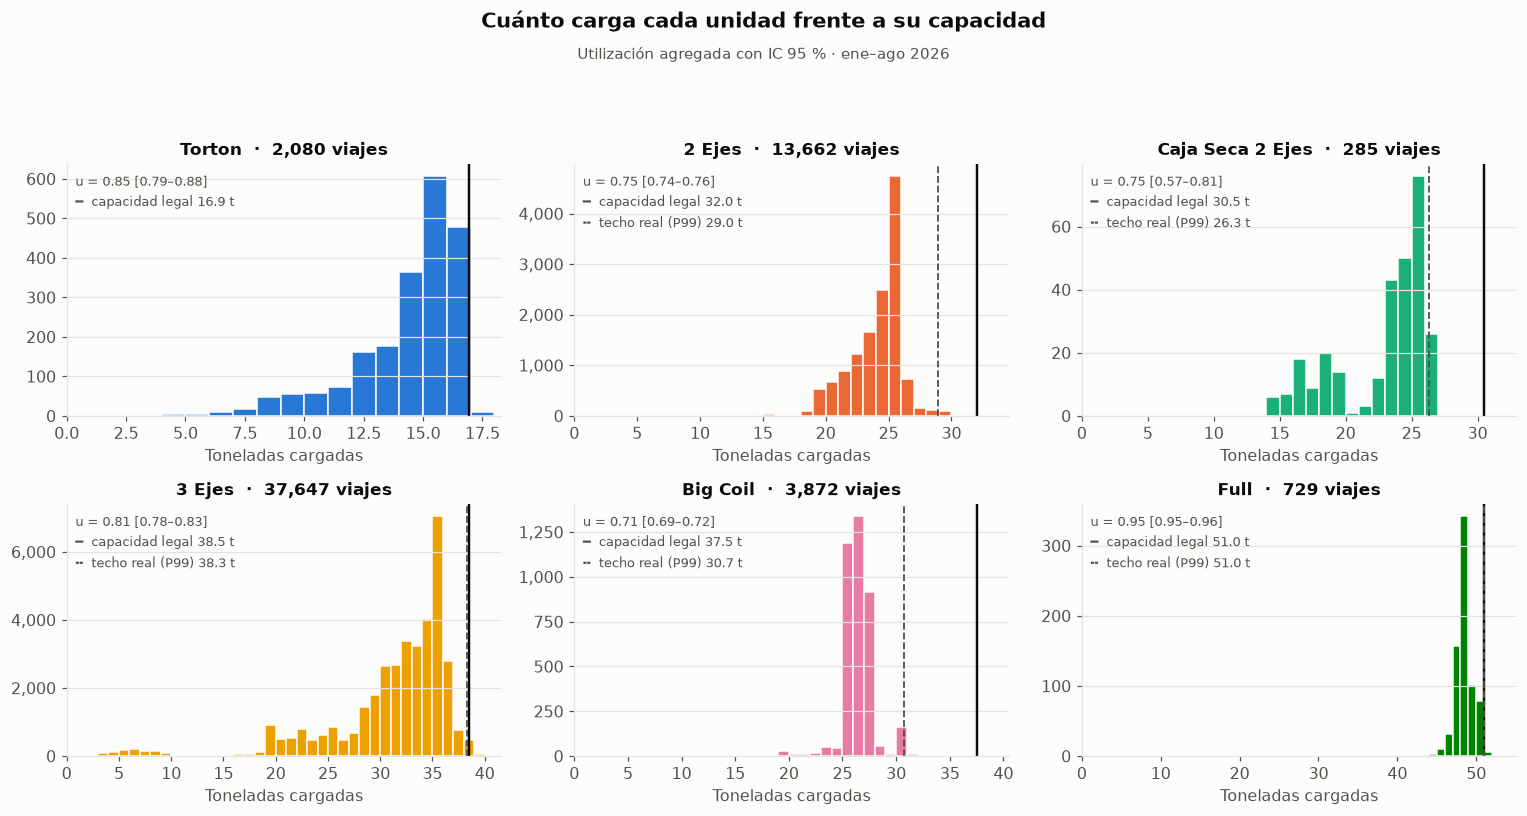

In [7]:
# FIG — Cuánto carga cada unidad frente a su capacidad (con la utilización agregada y su IC 95 %)
fig, axes = plt.subplots(2, 3, figsize=(14, 7.5))
for ax, u in zip(axes.flat, UNIDADES):
    q = df.loc[df['Unidad'] == u, 'Toneladas_Reales']
    c_leg, p99 = cap.loc[u, 'Cap_central_t'], cap.loc[u, 'Techo_P99_t']
    ax.hist(q, bins=np.arange(0, c_leg + 3, 1), color=COLOR_UNIDAD[u], edgecolor=SUPERFICIE, linewidth=1)
    ax.axvline(c_leg, color=TINTA, lw=1.6)
    r = por_unidad.loc[u]
    txt = f'u = {r.u_agregada:.2f} [{r.u_IC_inf:.2f}–{r.u_IC_sup:.2f}]\n━  capacidad legal {c_leg:.1f} t'
    if u != 'Torton':                                      # en Torton la capacidad ya es el P99
        ax.axvline(p99, color=TINTA_2, lw=1.2, ls='--')
        txt += f'\n╍  techo real (P99) {p99:.1f} t'
    ax.text(0.02, 0.97, txt, transform=ax.transAxes, va='top', fontsize=8.8, color=TINTA_2, linespacing=1.5)
    ax.set_xlim(0, c_leg * 1.08)
    ax.set_title(f'{u}  ·  {len(q):,} viajes', fontsize=11)
    ax.set_xlabel('Toneladas cargadas'); ax.grid(axis='x', visible=False)
    ax.yaxis.set_major_formatter(mtick.StrMethodFormatter('{x:,.0f}'))
titulo(fig, 'Cuánto carga cada unidad frente a su capacidad', 'Utilización agregada con IC 95 % · ene–ago 2026')
plt.show()

In [8]:
# Sensibilidad a la elección del conglomerado (justificación del esquema de dos vías)
ESQUEMAS = {'Viaje (sin conglomerar)': ['ID_VIAJE'], 'Semana': ['Semana_Egreso'], 'Ruta': ['Ruta_ID'],
            'Transportista': ['Transportista'], 'Transportista × ruta': CONGLOMERADOS}
sens = {}
for nombre, cong in ESQUEMAS.items():
    r = bootstrap_utilizacion(df, ['Unidad'], conglomerados=cong, B=1000).reindex(UNIDADES)
    sens[nombre] = ((r['u_IC_sup'] - r['u_IC_inf']) / 2 * 100).round(1)
print('Semiancho del IC 95 % de la utilización (puntos porcentuales) según qué se remuestrea (B = 1000)')
display(pd.DataFrame(sens))
print('Viaje y semana subestiman la incertidumbre; con solo transportistas, Big Coil (12) y caja seca (1) salen casi sin IC.')

Semiancho del IC 95 % de la utilización (puntos porcentuales) según qué se remuestrea (B = 1000)


,Viaje (sin conglomerar),Semana,Ruta,Transportista,Transportista × ruta
Unidad,,,,,
Torton,0.6,0.8,1.4,4.1,4.5
2 Ejes,0.1,0.3,0.8,0.9,1.2
Caja Seca 2 Ejes,1.3,1.8,11.8,0.0,11.8
3 Ejes,0.2,0.3,1.4,1.9,2.5
Big Coil,0.1,0.3,1.5,0.5,1.6
Full,0.2,0.2,0.1,0.6,0.7


Viaje y semana subestiman la incertidumbre; con solo transportistas, Big Coil (12) y caja seca (1) salen casi sin IC.


### 4.3 Utilización por planta × unidad

Celdas con ≥ 30 viajes.

In [9]:
# Propósito: Utilización por planta × unidad con IC (celdas con ≥ 30 viajes) y % de viajes a menos de media capacidad.
MIN_TRANS = 5   # con menos transportistas el IC es menos estable
pu = bootstrap_utilizacion(df, [GRUPO, PLANTA, 'Unidad'])
pu = pu[pu['Viajes'] >= 30].reset_index()
pu['Unidad'] = pd.Categorical(pu['Unidad'], UNIDADES, ordered=True)
pu = pu.sort_values([GRUPO, PLANTA, 'Unidad']).set_index([GRUPO, PLANTA, 'Unidad'])
pu['IC_confiable'] = pu['Transportistas'] >= MIN_TRANS
U_BAJA = 0.5   # viajes a menos de la mitad de su capacidad: candidatos directos a otra unidad
pu['% viajes u<0.5'] = (df.assign(baja=df['u'] < U_BAJA)
                          .groupby([GRUPO, PLANTA, 'Unidad'], observed=True)['baja'].mean()
                          .reindex(pu.index) * 100).round(1)

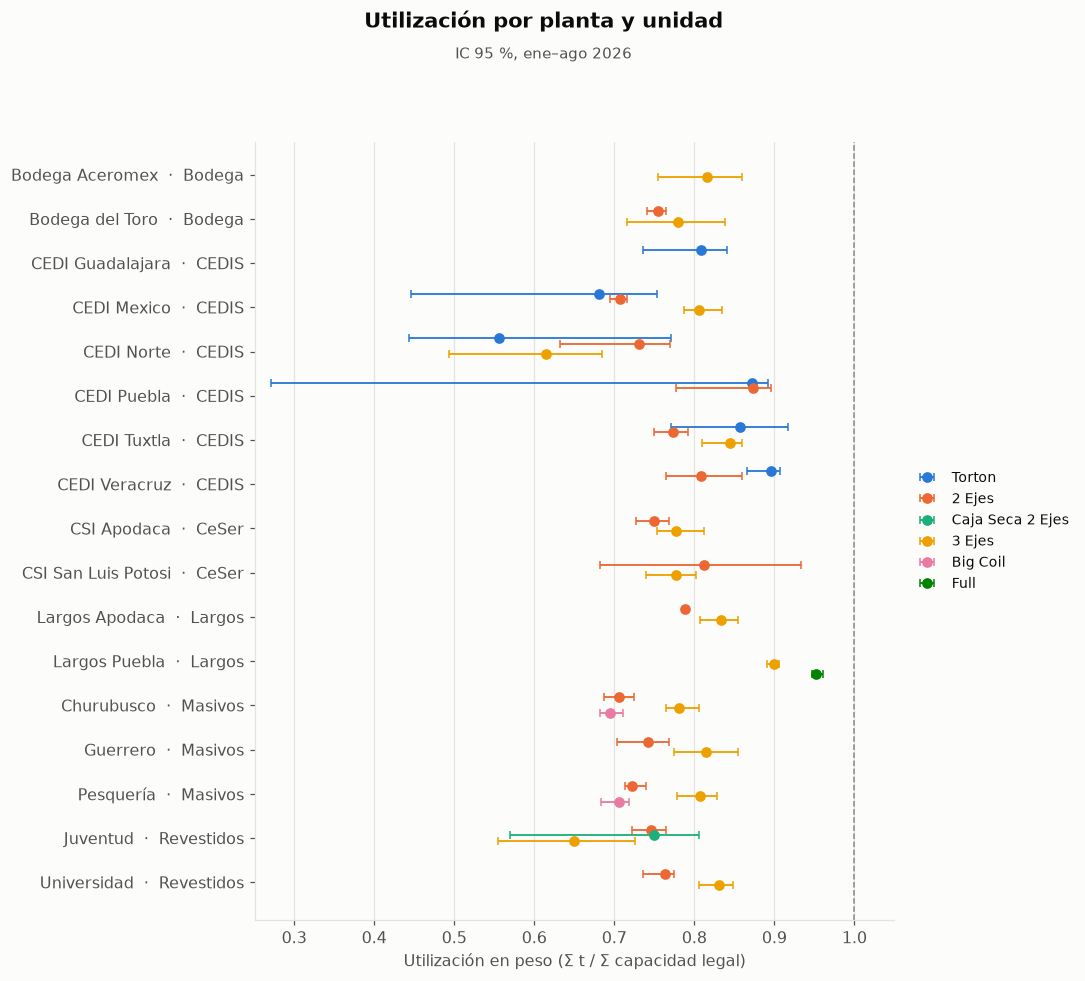

In [10]:
# FIG — Utilización por planta y unidad con IC 95 % (cada unidad se desplaza un poco en vertical dentro de su planta)
g = pu.reset_index()
g['Etiqueta'] = g[PLANTA] + '  ·  ' + g[GRUPO]
orden = list(dict.fromkeys(g.sort_values([GRUPO, PLANTA])['Etiqueta']))
desp = dict(zip(UNIDADES, np.linspace(-0.3, 0.3, len(UNIDADES))))
fig, ax = plt.subplots(figsize=(10, 9))
for u in UNIDADES:
    s = g[g['Unidad'] == u]
    if s.empty: continue
    y = [orden.index(e) + desp[u] for e in s['Etiqueta']]
    ax.errorbar(s['u_agregada'], y, xerr=[s['u_agregada'] - s['u_IC_inf'], s['u_IC_sup'] - s['u_agregada']],
                fmt='o', color=COLOR_UNIDAD[u], label=u, capsize=2.5, ms=6, elinewidth=1.2)
ax.set_yticks(range(len(orden)), orden); ax.invert_yaxis()
ax.axvline(1, color=TINTA_3, lw=1, ls='--')
ax.set_xlabel('Utilización en peso (Σ t / Σ capacidad legal)')
ax.set_xlim(min(0.4, g['u_IC_inf'].min() - 0.02), 1.05); ax.grid(axis='y', visible=False)
ax.legend(loc='center left', bbox_to_anchor=(1.01, 0.5), fontsize=9)
titulo(fig, 'Utilización por planta y unidad', 'IC 95 %, ene–ago 2026')
plt.show()

## 5. ¿Cuánto cuesta la capacidad ociosa?

La tarifa de un viaje es fija por ruta × unidad × transportista: no cambia con el peso cargado (sección de hallazgos: CV mediano 3.1 %, elasticidad costo-peso 0.02). Entonces, cuando un camión va a una fracción *uᵢ* de su capacidad, Ternium paga el viaje completo pero solo aprovecha esa fracción. Definimos el **costo de la capacidad ociosa** del viaje *i* como la parte de la tarifa que corresponde a la capacidad no usada:

$$\text{CO}_i = C_i\,(1 - \min(u_i, 1))$$

**Relación con el costo por tonelada-km.** Si el camión fuera lleno, el costo por tonelada-km sería $C_i/(c_i\,d_i)$ en vez de $C_i/(q_i\,d_i)$. La diferencia multiplicada por las toneladas-km movidas es exactamente $\text{CO}_i$:

$$\Big(\tfrac{C_i}{q_i d_i} - \tfrac{C_i}{c_i d_i}\Big)\, q_i d_i = C_i\,(1-u_i).$$

Es decir, el costo ocioso en pesos es la **penalización en costo por tonelada-km** por viajar con capacidad libre, sumada sobre lo que se movió. Ambas lecturas dan el mismo número.

**Qué es y qué no es.** CO mide **el tamaño del problema**, no el ahorro alcanzable: recuperarlo todo exigiría que cada camión saliera lleno (consolidación perfecta), lo cual no siempre es posible por fechas, destinos y clientes. Además, como *u* en peso es cota inferior, CO es **cota superior**. El ahorro alcanzable se estima en la sección siguiente (right-sizing: misma carga en una unidad más barata que ya opera la ruta).

Se reportan dos versiones:
- **Contra la capacidad legal** (NOM-012 − tara): todo lo que la ley permitiría cargar.
- **Contra el techo operativo** (P99 observado por unidad): solo la holgura que la operación sí usa en otros viajes. La diferencia es holgura legal que hoy nadie usa (p. ej., el tope de ~26 t en 2 ejes); hasta que Ternium explique ese tope no se puede llamar accionable.

IC 95 %: bootstrap de dos vías transportista × ruta (mismo esquema que la sección 4). Los totales en pesos se obtienen como (proporción ociosa con su IC) × gasto observado de la celda.

### 5.1 Costo ocioso por unidad

In [11]:
# Columnas por viaje
df['Costo'] = df['Monto total']
df['u_op'] = df['Toneladas_Reales'] / df['Techo_P99_t']                     # utilización contra techo operativo
df['CO_legal'] = df['Costo'] * (1 - df['u'].clip(upper=1))                  # costo de la capacidad legal no usada
df['CO_oper']  = df['Costo'] * (1 - df['u_op'].clip(upper=1))               # … de la holgura que la operación sí usa
df['CO_holgura'] = (df['CO_legal'] - df['CO_oper']).clip(lower=0)           # holgura legal por encima del techo operativo

bootstrap_razones = bootstrap_conglomerados   # mismo esquema de dos vías de la sección 4

SUMAS = {'Gasto': 'Costo', 'CO_legal': 'CO_legal', 'CO_oper': 'CO_oper', 'Ociosa_t': 'Ociosa_t'}
RAZONES = {'pct_CO_legal': ('CO_legal', 'Gasto'),      # fracción del gasto que paga capacidad legal no usada
           'pct_CO_oper':  ('CO_oper', 'Gasto'),       # … capacidad bajo el techo operativo
           'MXN_t_ociosa': ('CO_legal', 'Ociosa_t')}   # lo que cuesta, en promedio, cada tonelada no cargada

def con_totales(res):
    """Totales en millones de MXN con IC = proporción (con IC) × gasto observado."""
    for k, p in [('CO_legal', 'pct_CO_legal'), ('CO_oper', 'pct_CO_oper')]:
        for s in ['', '_inf', '_sup']:
            res[f'{k}_M{s}'] = res[f'{p}{s}'] * res['Gasto'] / 1e6
    res['Gasto_M'] = res['Gasto'] / 1e6
    return res

co_u = con_totales(bootstrap_razones(df, ['Unidad'], SUMAS, RAZONES).reindex(UNIDADES))
co_tot = con_totales(bootstrap_razones(df.assign(Todo='Universo'), ['Todo'], SUMAS, RAZONES))
co_tab = pd.concat([co_u, co_tot.rename(index={'Universo': 'Total universo'})])

fmt = lambda r, k, d=1, esc=1: f"{r[k]*esc:,.{d}f} [{r[k+'_inf']*esc:,.{d}f}–{r[k+'_sup']*esc:,.{d}f}]"
print('Costo de la capacidad ociosa, ene–ago 2026 (M MXN; IC 95 %, bootstrap transportista × ruta)')
display(pd.DataFrame({
    'Gasto': co_tab['Gasto_M'].round(0),
    'Costo ocioso [IC 95%]': co_tab.apply(fmt, axis=1, k='CO_legal_M', d=0),
    '% del gasto [IC 95%]': co_tab.apply(fmt, axis=1, k='pct_CO_legal', esc=100),
    '% contra techo real P99': (co_tab['pct_CO_oper'] * 100).round(1),
}))

Costo de la capacidad ociosa, ene–ago 2026 (M MXN; IC 95 %, bootstrap transportista × ruta)


,Gasto,Costo ocioso [IC 95%],% del gasto [IC 95%],% contra techo real P99
Torton,30.0,4 [4–6],14.9 [11.8–20.5],14.9
2 Ejes,449.0,112 [108–117],24.9 [23.9–26.2],17.1
Caja Seca 2 Ejes,6.0,2 [1–3],31.1 [19.4–43.1],20.1
3 Ejes,1043.0,202 [176–230],19.4 [16.9–22.0],19.0
Big Coil,69.0,20 [19–22],29.8 [28.4–31.4],14.5
Full,39.0,2 [2–2],4.8 [3.9–5.2],4.8
Total universo,1636.0,343 [302–378],20.9 [18.5–23.1],17.9


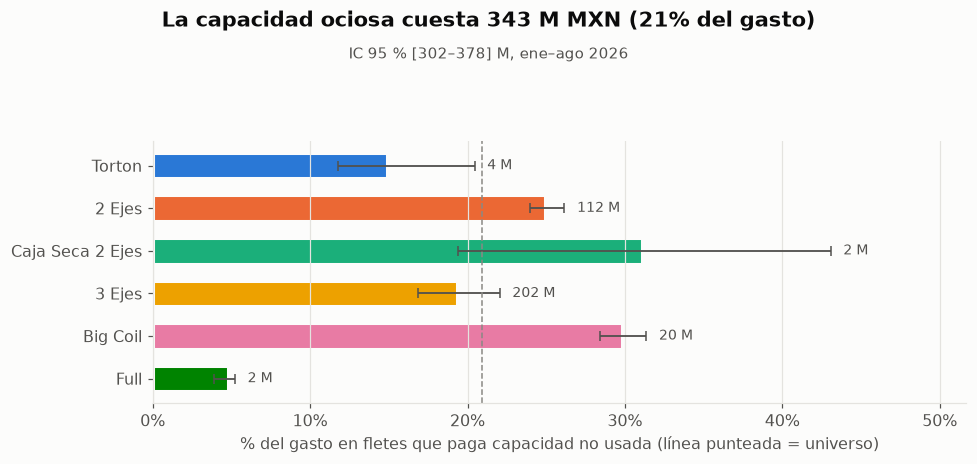

In [12]:
# FIG — Qué fracción del gasto paga capacidad no usada, por unidad
d = co_u.iloc[::-1]
fig, ax = plt.subplots(figsize=(9, 4.3))
ax.barh(d.index, d['pct_CO_legal'] * 100, color=[COLOR_UNIDAD[u] for u in d.index], height=0.6,
        edgecolor=SUPERFICIE, linewidth=2)
ax.errorbar(d['pct_CO_legal'] * 100, range(len(d)),
            xerr=[(d['pct_CO_legal'] - d['pct_CO_legal_inf']) * 100, (d['pct_CO_legal_sup'] - d['pct_CO_legal']) * 100],
            fmt='none', ecolor=TINTA_2, elinewidth=1.2, capsize=3)
for y, (u, r) in enumerate(d.iterrows()):
    ax.text(r['pct_CO_legal_sup'] * 100 + 0.8, y, f"{r['CO_legal_M']:.0f} M", va='center', fontsize=9, color=TINTA_2)
t = co_tot.iloc[0]
ax.axvline(t['pct_CO_legal'] * 100, color=TINTA_3, lw=1, ls='--')
ax.set_xlim(0, d['pct_CO_legal_sup'].max() * 100 * 1.2); ax.grid(axis='y', visible=False)
ax.xaxis.set_major_formatter(mtick.PercentFormatter())
ax.set_xlabel('% del gasto en fletes que paga capacidad no usada (línea punteada = universo)')
titulo(fig, f'La capacidad ociosa cuesta {t["CO_legal_M"]:.0f} M MXN ({t["pct_CO_legal"]:.0%} del gasto)',
       f'IC 95 % [{t["CO_legal_M_inf"]:.0f}–{t["CO_legal_M_sup"]:.0f}] M, ene–ago 2026')
plt.show()

### 5.2 Costo ocioso por planta × unidad

In [13]:
# Propósito: Costo ocioso por planta × unidad (celdas con ≥ 30 viajes), de mayor a menor, con % acumulado.
co_pu = con_totales(bootstrap_razones(df, [GRUPO, PLANTA, 'Unidad'], SUMAS, RAZONES))
co_pu = co_pu[co_pu['Viajes'] >= 30].reset_index()
co_pu['Unidad'] = pd.Categorical(co_pu['Unidad'], UNIDADES, ordered=True)
co_pu = co_pu.sort_values('CO_legal_M', ascending=False).set_index([GRUPO, PLANTA, 'Unidad'])
co_pu['IC_confiable'] = co_pu['Transportistas'] >= MIN_TRANS
co_pu['% acumulado'] = co_pu['CO_legal_M'].cumsum() / co_pu['CO_legal_M'].sum() * 100

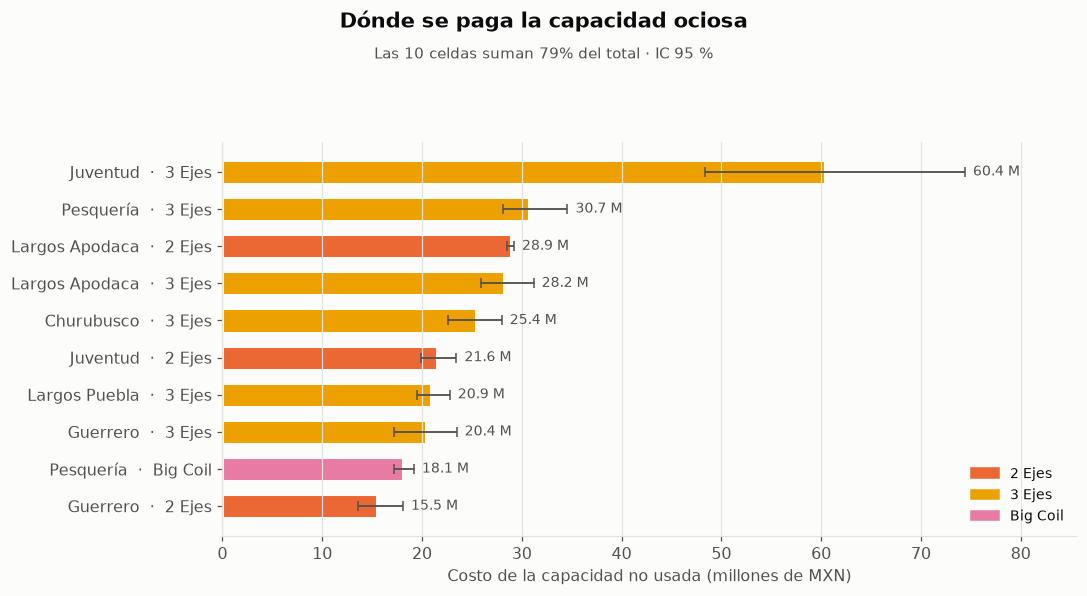

In [14]:
# FIG — Dónde se paga la capacidad ociosa (10 celdas con mayor costo)
top = co_pu.head(10).reset_index().iloc[::-1]
etq = top[PLANTA] + '  ·  ' + top['Unidad'].astype(str)
fig, ax = plt.subplots(figsize=(10, 5.5))
ax.barh(etq, top['CO_legal_M'], color=[COLOR_UNIDAD[u] for u in top['Unidad']], height=0.65,
        edgecolor=SUPERFICIE, linewidth=2)
ax.errorbar(top['CO_legal_M'], range(len(top)),
            xerr=[top['CO_legal_M'] - top['CO_legal_M_inf'], top['CO_legal_M_sup'] - top['CO_legal_M']],
            fmt='none', ecolor=TINTA_2, elinewidth=1.2, capsize=3)
for y, r in enumerate(top.itertuples()):
    ax.text(r.CO_legal_M_sup + 0.8, y, f'{r.CO_legal_M:.1f} M', va='center', fontsize=9, color=TINTA_2)
ax.set_xlim(0, top['CO_legal_M_sup'].max() * 1.15); ax.grid(axis='y', visible=False)
ax.set_xlabel('Costo de la capacidad no usada (millones de MXN)')
leyenda_unidades(ax, [u for u in UNIDADES if u in set(top['Unidad'].astype(str))], loc='lower right', fontsize=9)
titulo(fig, 'Dónde se paga la capacidad ociosa',
       f'Las 10 celdas suman {top["CO_legal_M"].sum() / co_pu["CO_legal_M"].sum():.0%} del total · IC 95 %')
plt.show()

### 5.3 Penalización en costo por tonelada-km

Como la tarifa tiene un componente fijo, el costo por tonelada-km baja con la distancia: la comparación se hace **dentro de bandas de distancia**. Para cada unidad y banda: costo por t-km real (Σ costo / Σ t-km) y el que tendría con la misma tarifa a capacidad legal (Σ costo / Σ capacidad·km). Solo viajes con km confiable y celdas con ≥ 30 viajes.

In [15]:
# Propósito: Costo por tonelada-km real contra el que habría con el camión lleno, por unidad y banda de distancia.
# Solo viajes con km confiable.
BANDAS = [0, 300, 600, 1000, np.inf]
ETQ_BANDA = ['< 300 km', '300–600 km', '600–1,000 km', '> 1,000 km']
dk = df[df['Km_Confiable'] & df['Kilometros_Ruta'].gt(0)].copy()
dk['Banda'] = pd.cut(dk['Kilometros_Ruta'], BANDAS, labels=ETQ_BANDA, right=False)
# tkm = toneladas movidas × km; ckm = capacidad × km (lo que se movería con el camión lleno)
dk['tkm'] = dk['Toneladas_Reales'] * dk['Kilometros_Ruta']
dk['ckm'] = dk['Cap_central_t'] * dk['Kilometros_Ruta']
dk['Unidad_s'] = dk['Unidad'].astype(str)
ctk = bootstrap_razones(dk, ['Unidad_s', 'Banda'],
                        {'Gasto': 'Costo', 'tkm': 'tkm', 'ckm': 'ckm'},
                        {'MXN_tkm_real': ('Gasto', 'tkm'), 'MXN_tkm_lleno': ('Gasto', 'ckm')})
ctk = ctk[ctk['Viajes'] >= 30]
ctk['Penalización %'] = (ctk['MXN_tkm_real'] / ctk['MXN_tkm_lleno'] - 1) * 100   # = 1/u − 1
ctk = ctk.reset_index()
ctk['Unidad_s'] = pd.Categorical(ctk['Unidad_s'], UNIDADES, ordered=True)
ctk['Banda'] = pd.Categorical(ctk['Banda'], ETQ_BANDA, ordered=True)
ctk = ctk.sort_values(['Unidad_s', 'Banda']).set_index(['Unidad_s', 'Banda'])
print(f'Viajes con km confiable: {len(dk):,} de {len(df):,} ({len(dk)/len(df):.1%}). Celdas con ≥ 30 viajes.')

Viajes con km confiable: 55,202 de 58,275 (94.7%). Celdas con ≥ 30 viajes.


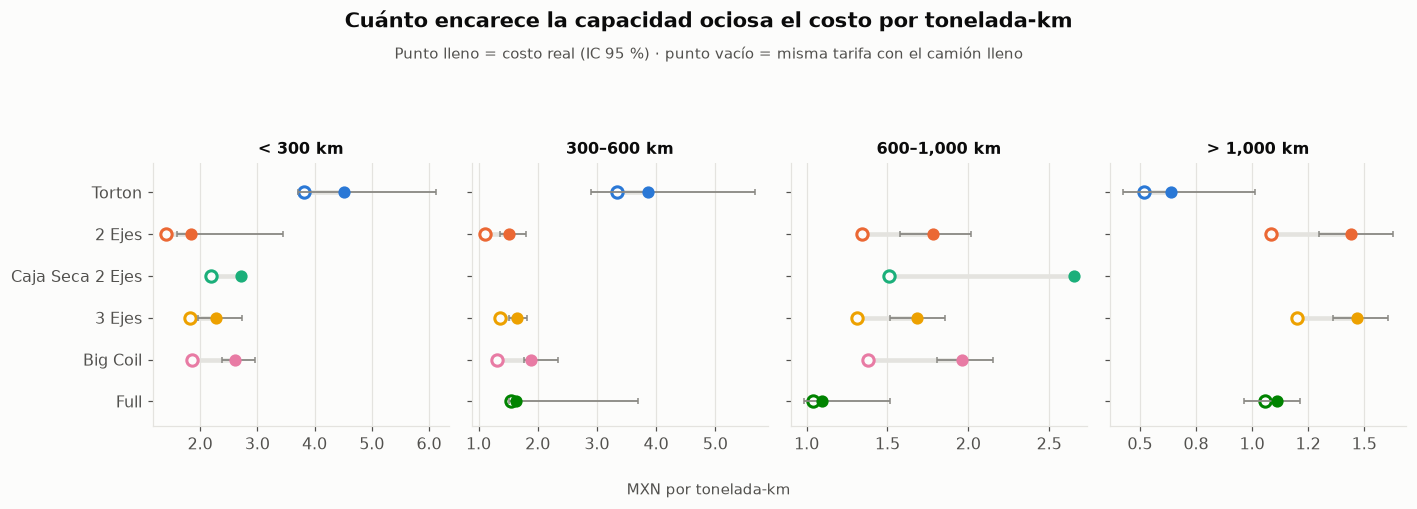

In [16]:
# FIG — costo por t-km real vs. a capacidad llena, por banda de distancia
fig, axs = plt.subplots(1, len(ETQ_BANDA), figsize=(13, 4.6), sharey=True)
for ax, b in zip(axs, ETQ_BANDA):
    s = ctk.xs(b, level='Banda') if b in ctk.index.get_level_values('Banda') else ctk.iloc[:0]
    for u in [u for u in UNIDADES if u in s.index]:
        y, r = UNIDADES.index(u), s.loc[u]
        ax.plot([r['MXN_tkm_lleno'], r['MXN_tkm_real']], [y, y], color=REJILLA, lw=3, zorder=1)
        ax.scatter(r['MXN_tkm_lleno'], y, s=55, facecolor=SUPERFICIE, edgecolor=COLOR_UNIDAD[u], lw=2, zorder=3)
        ax.errorbar(r['MXN_tkm_real'], y, xerr=[[r['MXN_tkm_real'] - r['MXN_tkm_real_inf']],
                                                [r['MXN_tkm_real_sup'] - r['MXN_tkm_real']]],
                    fmt='o', ms=7, color=COLOR_UNIDAD[u], ecolor=TINTA_3, elinewidth=1.2, capsize=2, zorder=4)
    ax.set_yticks(range(len(UNIDADES)), UNIDADES); ax.set_title(b, fontsize=10.5)
    ax.set_ylim(-0.7, len(UNIDADES) - 0.4); ax.grid(axis='y', visible=False)
    ax.xaxis.set_major_formatter(mtick.FormatStrFormatter('%.1f'))
axs[0].invert_yaxis()
fig.supxlabel('MXN por tonelada-km', fontsize=10, color=TINTA_2)
titulo(fig, 'Cuánto encarece la capacidad ociosa el costo por tonelada-km',
       'Punto lleno = costo real (IC 95 %) · punto vacío = misma tarifa con el camión lleno')
plt.show()

## 6. Right-sizing: ¿qué cargas pueden ir en otra unidad?

**Pregunta.** Para cada viaje, con su carga *q* y su ruta *r* (planta → destino), ¿existe otra unidad que la lleve legalmente y que cueste menos en esa misma ruta? Si existe, la carga se mueve a la más barata. Es el núcleo del modelo final: entra peso programado + destino, sale la unidad más eficiente.

**Reglas (declaradas):**
1. **Tarifa de referencia** T(r, k): mediana del costo por viaje de la unidad *k* en la ruta *r*, entre todos sus transportistas. Requiere ≥ 5 viajes. Se compara la tarifa de referencia de la unidad actual contra la de la alternativa **en la misma ruta**, así que el ahorro es el efecto de cambiar de unidad, no de cambiar de transportista.
2. **Factible** si: (a) *q* ≤ capacidad de la alternativa; (b) la alternativa ya opera esa ruta con tarifa de referencia. Como la ruta sale de una planta, (b) implica que la unidad ya carga ese grupo de producto: con eso quedan cubiertas las reglas de Largos (solo 2 ejes, 3 ejes y Full) y del Big Coil (a 3 ejes o 2 ejes); (c) no se pasa carga de **caja seca** (cerrada) a plataforma abierta, porque puede ser producto que requiere protección. Al revés sí está permitido.
3. **Capacidad para decidir**: la menor entre la carga útil legal y el techo operativo (P99 observado). Es conservador: el 2 ejes queda en 29.0 t y el Big Coil en 30.7 t. Con capacidad legal se reporta como sensibilidad.
4. **Decisión**: la unidad factible con menor tarifa (desempate: mayor utilización). Solo se mueve si es al menos **3 % más barata** que la actual: el CV mediano de la tarifa dentro de ruta × unidad × transportista es 3.1 %, así que diferencias menores no se distinguen del ruido.

**Métricas.** En tonelaje (indicación de Ternium): capacidad contratada que se libera, utilización y capacidad ociosa antes y después. En dinero: ahorro = T(r, k) − T(r, k*). Los movimientos se separan en **bajar de unidad** (mejora utilización y ahorra) y **subir de unidad** (ahorra, pero empeora la utilización).

**Incertidumbre.** Bootstrap de dos vías transportista × ruta (B = 1000). La decisión se toma una sola vez, con las tarifas observadas; en cada réplica se **recalculan las tarifas de referencia** con los pesos remuestreados (mediana ponderada) y se evalúan **los mismos movimientos**. Así el IC responde a la pregunta relevante, "si se ejecutan estos movimientos, ¿cuánto se ahorra?", y puede ser negativo: un movimiento basado en una diferencia de tarifa pequeña puede salir más caro con otra muestra de tarifas. (Volver a decidir en cada réplica acotaría el IC en cero por construcción y lo sesgaría hacia arriba.)

**Lo que no incluye:** consolidar dos viajes ligeros en uno (requiere fechas y destinos compatibles), reasignar transportistas, ni rutas donde la alternativa no tiene tarifa observada (ahí haría falta un modelo de tarifa).

In [17]:
# ---------- 6.1 Parámetros y decisión por viaje ----------
N_MIN_TARIFA = 5        # viajes mínimos de la unidad en la ruta para tener tarifa de referencia
DELTA_MIN = 0.03        # la alternativa debe ser ≥ 3 % más barata
B_RS = 1000
CERRADAS = {'Caja Seca 2 Ejes'}
K = len(UNIDADES)
PERMITIDO = np.array([[not (a in CERRADAS and b not in CERRADAS) for b in UNIDADES] for a in UNIDADES])

CAP_LEGAL = cap['Cap_central_t'].reindex(UNIDADES).values
CAP_OPER = np.minimum(cap['Cap_central_t'], cap['Techo_P99_t']).reindex(UNIDADES).values

rs = df[['Ruta_ID', 'Transportista', GRUPO, PLANTA, 'Toneladas_Reales', 'Costo', 'Cap_central_t']].copy()
rs['k'] = df['Unidad'].cat.codes.values                                   # índice de la unidad actual
celdas = rs.groupby(['Ruta_ID', 'k']).size()
celdas = celdas[celdas >= N_MIN_TARIFA].index                              # (ruta, unidad) con tarifa
rutas = pd.Index(rs['Ruta_ID'].unique())
rs['r'] = rutas.get_indexer(rs['Ruta_ID'])
rs['celda'] = pd.MultiIndex.from_arrays([rs['Ruta_ID'], rs['k']]).isin(celdas)
cel_r, cel_k = rutas.get_indexer(celdas.get_level_values(0)), celdas.get_level_values(1).values

# Mediana ponderada por celda (ruta, unidad), vectorizada: se ordena una vez y se reusa en cada réplica
sub = rs[rs['celda']].copy()
sub['cid'] = pd.MultiIndex.from_arrays([sub['Ruta_ID'], sub['k']]).map(
    pd.Series(np.arange(len(celdas)), index=celdas))
orden = np.lexsort((sub['Costo'].values, sub['cid'].values))
costo_ord, cid_ord = sub['Costo'].values[orden], sub['cid'].values[orden]
pos_en_rs = rs.index.get_indexer(sub.index[orden])                         # posición en rs de cada viaje ordenado
ini = np.searchsorted(cid_ord, np.arange(len(celdas)), 'left')
fin = np.searchsorted(cid_ord, np.arange(len(celdas)), 'right')

def tarifas(w):
    """Matriz rutas × unidades con la mediana ponderada del costo (NaN si no hay tarifa)."""
    ws = w[pos_en_rs]
    cum = np.concatenate([[0.0], np.cumsum(ws)])
    tot = cum[fin] - cum[ini]
    obj = cum[ini] + tot / 2
    j = np.clip(np.searchsorted(cum, obj, 'left') - 1, ini, np.maximum(fin - 1, ini))
    T = np.full((len(rutas), K), np.nan)
    T[cel_r, cel_k] = np.where(tot > 0, costo_ord[j], np.nan)
    return T

def decidir(T, cap_dec, delta=DELTA_MIN):
    """Unidad elegida por viaje: la factible más barata (desempate: mayor u); se mueve solo si ahorra ≥ delta."""
    q, k = rs['Toneladas_Reales'].values, rs['k'].values
    Tr = T[rs['r'].values]                                                 # viajes × unidades
    fact = ~np.isnan(Tr) & (q[:, None] <= cap_dec[None, :]) & PERMITIDO[k]
    t_act = Tr[np.arange(len(rs)), k]
    clave = np.where(fact, Tr + 1e-6 * cap_dec[None, :], np.inf)          # desempate: menor capacidad = mayor u
    k_best = clave.argmin(1)
    t_best = Tr[np.arange(len(rs)), k_best]
    mueve = ~np.isnan(t_act) & fact.any(1) & (k_best != k) & (t_best <= (1 - delta) * t_act)
    k_new = np.where(mueve, k_best, k)
    ahorro = np.where(mueve, t_act - t_best, 0.0)
    return k_new, ahorro, mueve, ~np.isnan(t_act)

T_obs = tarifas(np.ones(len(rs)))
k_new, ahorro, mueve, con_tarifa = decidir(T_obs, CAP_OPER)
rs['Unidad'] = df['Unidad'].astype(str).values
rs['Unidad_RS'] = np.array(UNIDADES)[k_new]
rs['Ahorro_RS'] = ahorro
rs['Mueve'] = mueve
rs['Con_tarifa'] = con_tarifa
rs['Cap_RS_t'] = CAP_LEGAL[k_new]                                          # la utilización se mide contra la capacidad legal
rs['Tipo_mov'] = np.select([~mueve, CAP_LEGAL[k_new] < CAP_LEGAL[rs['k']]], ['Sin cambio', 'Bajar de unidad'], 'Subir de unidad')

print(f'Viajes con tarifa de referencia en su propia unidad y ruta: {con_tarifa.sum():,} de {len(rs):,} ({con_tarifa.mean():.1%})')
print(f'Viajes que se mueven: {mueve.sum():,} ({mueve.mean():.1%}); ahorro puntual {ahorro.sum()/1e6:,.1f} M MXN '
      f'({ahorro.sum()/rs["Costo"].sum():.1%} del gasto)')

Viajes con tarifa de referencia en su propia unidad y ruta: 56,288 de 58,275 (96.6%)
Viajes que se mueven: 5,784 (9.9%); ahorro puntual 38.5 M MXN (2.4% del gasto)


In [18]:
# ---------- 6.2 Bootstrap de dos vías: movimientos fijos evaluados con tarifas recalculadas ----------
def pesos_dos_vias(rng, n_rep):
    w = np.ones((n_rep, len(rs)))
    for col in CONGLOMERADOS:
        cod, uniq = pd.factorize(rs[col]); m = len(uniq)
        w *= rng.multinomial(m, np.full(m, 1 / m), size=n_rep)[:, cod]
    return w

def metricas(k_n, ah, mov, w, grupos):
    """Sumas ponderadas por grupo (one-hot `grupos`, viajes × G) de lo que se reporta."""
    q, cl = rs['Toneladas_Reales'].values, rs['Cap_central_t'].values
    cn = CAP_LEGAL[k_n]
    baja = mov & (cn < cl)
    vals = {'gasto': rs['Costo'].values, 'ahorro': ah, 'ahorro_baja': np.where(baja, ah, 0),
            'ahorro_sube': np.where(mov & ~baja, ah, 0), 'mov': mov * 1.0, 'mov_baja': baja * 1.0,
            'q': q, 'cap_antes': cl, 'cap_despues': cn,
            'ociosa_antes': np.clip(cl - q, 0, None), 'ociosa_despues': np.clip(cn - q, 0, None)}
    return {k: (w * v) @ grupos for k, v in vals.items()}

def tabla_rs(grupo_col, B=B_RS, semilla=2026, cap_dec=CAP_OPER, delta=DELTA_MIN):
    g_codes, g_uniq = pd.factorize(rs[grupo_col] if isinstance(grupo_col, str) else pd.Series('Universo', index=rs.index))
    Gm = np.zeros((len(rs), len(g_uniq))); Gm[np.arange(len(rs)), g_codes] = 1
    kn, ah, mv, _ = decidir(T_obs, cap_dec, delta)
    obs = {k: v for k, v in metricas(kn, ah, mv, np.ones(len(rs)), Gm).items()}
    rng = np.random.default_rng(semilla)
    reps = {k: [] for k in ['pct_ahorro', 'pct_liberada', 'u_antes', 'u_despues']}
    for i in range(0, B, 100):
        W = pesos_dos_vias(rng, min(100, B - i))
        for w in W:
            T_b = tarifas(w)
            T_b = np.where(np.isnan(T_b), T_obs, T_b)          # celda vacía en la réplica: conserva su tarifa
            ah_b = np.where(mv, T_b[rs['r'].values, rs['k'].values] - T_b[rs['r'].values, kn], 0.0)
            m = metricas(kn, ah_b, mv, w, Gm)                   # mismos movimientos que la solución base
            with np.errstate(invalid='ignore', divide='ignore'):
                reps['pct_ahorro'].append(m['ahorro'] / m['gasto'])
                reps['pct_liberada'].append(1 - m['cap_despues'] / m['cap_antes'])
                reps['u_antes'].append(m['q'] / m['cap_antes'])
                reps['u_despues'].append(m['q'] / m['cap_despues'])
    res = pd.DataFrame(index=pd.Index(g_uniq, name=grupo_col if isinstance(grupo_col, str) else 'Universo'))
    res['Viajes'] = np.bincount(g_codes)
    res['Viajes movidos'] = obs['mov'].astype(int)
    res['Bajan de unidad'] = obs['mov_baja'].astype(int)
    res['Gasto_M'] = obs['gasto'] / 1e6
    res['Ahorro_M'] = obs['ahorro'] / 1e6
    res['Ahorro_bajar_M'] = obs['ahorro_baja'] / 1e6
    res['Ahorro_subir_M'] = obs['ahorro_sube'] / 1e6
    for k, v in reps.items():
        lo, hi = np.nanpercentile(np.array(v), [2.5, 97.5], axis=0)
        res[f'{k}_inf'], res[f'{k}_sup'] = lo, hi
    res['pct_ahorro'] = obs['ahorro'] / obs['gasto']
    res['Ahorro_M_inf'], res['Ahorro_M_sup'] = res['pct_ahorro_inf'] * res['Gasto_M'], res['pct_ahorro_sup'] * res['Gasto_M']
    res['Cap_liberada_kt'] = (obs['cap_antes'] - obs['cap_despues']) / 1e3
    res['pct_liberada'] = 1 - obs['cap_despues'] / obs['cap_antes']
    res['u_antes'], res['u_despues'] = obs['q'] / obs['cap_antes'], obs['q'] / obs['cap_despues']
    res['Ociosa_antes_kt'], res['Ociosa_despues_kt'] = obs['ociosa_antes'] / 1e3, obs['ociosa_despues'] / 1e3
    return res

rs_tot = tabla_rs(None)
r = rs_tot.iloc[0]
print(f"Right-sizing, universo (IC 95 %: mismos movimientos evaluados con tarifas por bootstrap de dos vías, B = {B_RS})")
print(f"  Viajes movidos: {int(r['Viajes movidos']):,} de {int(r['Viajes']):,} ({r['Viajes movidos']/r['Viajes']:.1%}); "
      f"{int(r['Bajan de unidad']):,} bajan de unidad")
print(f"  Ahorro: {r['Ahorro_M']:.1f} M MXN [{r['Ahorro_M_inf']:.1f}–{r['Ahorro_M_sup']:.1f}] = "
      f"{r['pct_ahorro']:.2%} [{r['pct_ahorro_inf']:.2%}–{r['pct_ahorro_sup']:.2%}] del gasto; "
      f"bajar {r['Ahorro_bajar_M']:.1f} M, subir {r['Ahorro_subir_M']:.1f} M")
print(f"  Capacidad contratada liberada: {r['Cap_liberada_kt']:.1f} mil t = {r['pct_liberada']:.2%} "
      f"[{r['pct_liberada_inf']:.2%}–{r['pct_liberada_sup']:.2%}]")
print(f"  Utilización de la flota: {r['u_antes']:.3f} → {r['u_despues']:.3f} [{r['u_despues_inf']:.3f}–{r['u_despues_sup']:.3f}]; "
      f"capacidad ociosa {r['Ociosa_antes_kt']:.0f} → {r['Ociosa_despues_kt']:.0f} mil t")
print(f"  Frente al costo de la capacidad ociosa (sección 5, {co_tot['CO_legal_M'].iloc[0]:.0f} M): "
      f"el right-sizing recupera {r['Ahorro_M']/co_tot['CO_legal_M'].iloc[0]:.0%}")

Right-sizing, universo (IC 95 %: mismos movimientos evaluados con tarifas por bootstrap de dos vías, B = 1000)
  Viajes movidos: 5,784 de 58,275 (9.9%); 4,915 bajan de unidad
  Ahorro: 38.5 M MXN [17.4–62.6] = 2.35% [1.06%–3.82%] del gasto; bajar 35.2 M, subir 3.3 M
  Capacidad contratada liberada: 23.3 mil t = 1.10% [0.24%–2.14%]
  Utilización de la flota: 0.791 → 0.799 [0.780–0.821]; capacidad ociosa 442 → 419 mil t
  Frente al costo de la capacidad ociosa (sección 5, 343 M): el right-sizing recupera 11%


In [19]:
# ---------- 6.3 Por movimiento y por planta ----------
rs['Movimiento'] = np.where(rs['Mueve'], rs['Unidad'] + ' → ' + rs['Unidad_RS'], 'Sin cambio')
rs_mov = tabla_rs('Movimiento').drop(index='Sin cambio').sort_values('Ahorro_M', ascending=False)
rs_mov['Tipo'] = rs.drop_duplicates('Movimiento').set_index('Movimiento')['Tipo_mov'].reindex(rs_mov.index)
rs_mov['t por viaje (mediana)'] = rs[rs['Mueve']].groupby('Movimiento')['Toneladas_Reales'].median().reindex(rs_mov.index)
_f = lambda d, a, b, esc=1, dec=1: d.apply(lambda x: f"{x[a]*esc:,.{dec}f} [{x[a+'_inf' if a+'_inf' in x else 'Ahorro_M_inf']*esc:,.{dec}f}–"
                                                  f"{x[a+'_sup' if a+'_sup' in x else 'Ahorro_M_sup']*esc:,.{dec}f}]", axis=1)

rs['Planta_U'] = rs[PLANTA] + ' · ' + rs['Unidad']
rs_pl = tabla_rs(PLANTA).sort_values('Ahorro_M', ascending=False)
rs_pl[GRUPO] = rs.drop_duplicates(PLANTA).set_index(PLANTA)[GRUPO].reindex(rs_pl.index)

In [20]:
# ---------- 6.4 Sensibilidad de las reglas ----------
# Benchmark alterno: solo viajes cuyo propio transportista tiene tarifa (≥ 2 viajes) en la unidad actual y en la sugerida,
# en la misma ruta; el ahorro es la diferencia de SUS medianas. Aísla el efecto de la unidad del de cambiar de transportista.
med_tr = rs.groupby(['Ruta_ID', 'Transportista', 'Unidad'])['Costo'].agg(['median', 'size'])
med_tr = med_tr[med_tr['size'] >= 2]['median']
m = rs[rs['Mueve']]
a = med_tr.reindex(pd.MultiIndex.from_arrays([m['Ruta_ID'], m['Transportista'], m['Unidad']])).values
b = med_tr.reindex(pd.MultiIndex.from_arrays([m['Ruta_ID'], m['Transportista'], m['Unidad_RS']])).values
ok = ~np.isnan(a) & ~np.isnan(b)
print(f'Benchmark dentro del mismo transportista: {ok.sum():,} de {len(m):,} viajes movidos tienen ambas tarifas propias.')
print(f'  En ellos: ahorro con medianas de ruta {m["Ahorro_RS"].values[ok].sum()/1e6:.1f} M vs. con tarifas del propio '
      f'transportista {np.sum(a[ok]-b[ok])/1e6:.1f} M; la unidad sugerida es más barata para ese transportista en '
      f'{np.mean(b[ok] < a[ok]):.0%} de los viajes.')

# Escenario estricto: capacidad = P95 observado (el 2 ejes queda en ~26 t, su techo habitual)
CAP_P95 = np.minimum(CAP_OPER, df.groupby(df['Unidad'].astype(str))['Toneladas_Reales'].quantile(.95).reindex(UNIDADES).values)
esc = []
for nombre, capd, dl in [('Base: capacidad operativa, umbral 3 %', CAP_OPER, 0.03),
                         ('Umbral 0 %', CAP_OPER, 0.0), ('Umbral 5 %', CAP_OPER, 0.05), ('Umbral 10 %', CAP_OPER, 0.10),
                         ('Capacidad estricta = P95 observado (2 ejes ≈ 26 t)', CAP_P95, 0.03),
                         ('Capacidad legal (2 ejes = 32 t)', CAP_LEGAL, 0.03)]:
    kn, ah, mv, _ = decidir(T_obs, capd, dl)
    baja = mv & (CAP_LEGAL[kn] < rs['Cap_central_t'].values)
    esc.append({'Escenario': nombre, 'Viajes movidos': int(mv.sum()), 'Bajan de unidad': int(baja.sum()),
                'Ahorro (M MXN)': round(ah.sum() / 1e6, 1), 'Ahorro bajando (M MXN)': round(ah[baja].sum() / 1e6, 1),
                'Capacidad liberada (mil t)': round((rs['Cap_central_t'].values - CAP_LEGAL[kn]).sum() / 1e3, 1)})
print('Sensibilidad de las reglas (estimación puntual)')
display(pd.DataFrame(esc).set_index('Escenario')[['Viajes movidos', 'Ahorro (M MXN)']])

Benchmark dentro del mismo transportista: 1,381 de 5,784 viajes movidos tienen ambas tarifas propias.
  En ellos: ahorro con medianas de ruta 12.7 M vs. con tarifas del propio transportista 10.4 M; la unidad sugerida es más barata para ese transportista en 84% de los viajes.
Sensibilidad de las reglas (estimación puntual)


,Viajes movidos,Ahorro (M MXN)
Escenario,,
"Base: capacidad operativa, umbral 3 %",5784,38.5
Umbral 0 %,8046,38.7
Umbral 5 %,5317,38.3
Umbral 10 %,4622,36.9
Capacidad estricta = P95 observado (2 ejes ≈ 26 t),4653,27.8
Capacidad legal (2 ejes = 32 t),9087,66.7


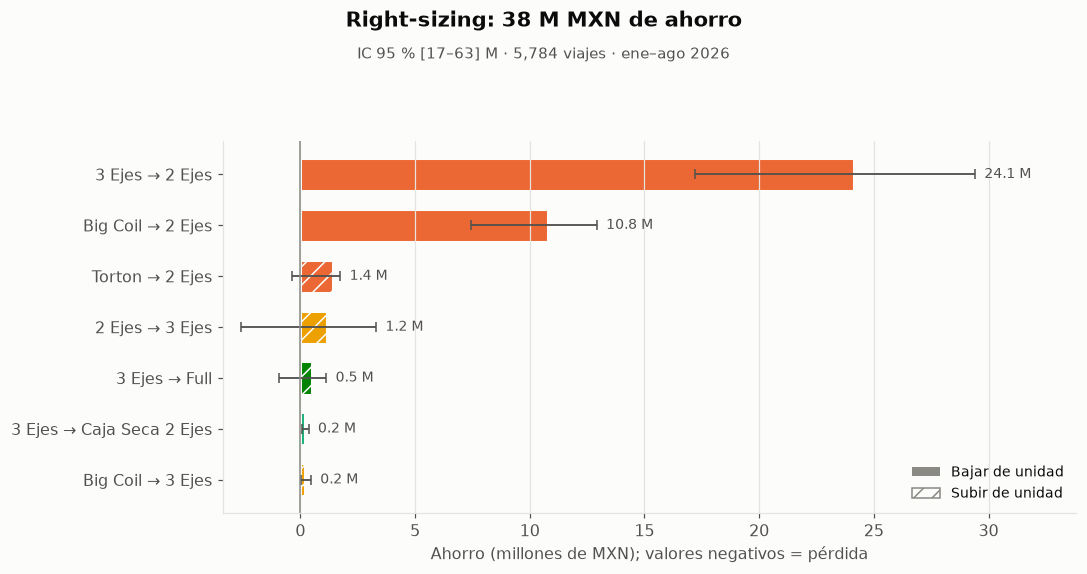

In [21]:
# FIG — Movimientos sugeridos
d = rs_mov[rs_mov['Viajes'] >= 30].iloc[::-1]
fig, ax = plt.subplots(figsize=(10, 0.5 * len(d) + 1.8))
dest = [m.split(' → ')[1] for m in d.index]
ax.barh(d.index, d['Ahorro_M'], color=[COLOR_UNIDAD[u] for u in dest], height=0.65, edgecolor=SUPERFICIE, linewidth=2,
        hatch=['' if t == 'Bajar de unidad' else '//' for t in d['Tipo']])
ax.errorbar(d['Ahorro_M'], range(len(d)), xerr=[d['Ahorro_M'] - d['Ahorro_M_inf'], d['Ahorro_M_sup'] - d['Ahorro_M']],
            fmt='none', ecolor=TINTA_2, elinewidth=1.2, capsize=3)
for y, (_, x) in enumerate(d.iterrows()):
    ax.text(x['Ahorro_M_sup'] + 0.4, y, f"{x['Ahorro_M']:.1f} M", va='center', fontsize=9, color=TINTA_2)
ax.set_xlim(min(0, d['Ahorro_M_inf'].min() * 1.3), d['Ahorro_M_sup'].max() * 1.15); ax.grid(axis='y', visible=False)
ax.axvline(0, color=TINTA_3, lw=1)
ax.set_xlabel('Ahorro (millones de MXN); valores negativos = pérdida')
ax.legend(handles=[Patch(facecolor=TINTA_3, label='Bajar de unidad'),
                   Patch(facecolor=SUPERFICIE, edgecolor=TINTA_3, hatch='//', label='Subir de unidad')],
          loc='lower right', fontsize=9)
r = rs_tot.iloc[0]
titulo(fig, f'Right-sizing: {r["Ahorro_M"]:.0f} M MXN de ahorro',
       f'IC 95 % [{r["Ahorro_M_inf"]:.0f}–{r["Ahorro_M_sup"]:.0f}] M · {int(r["Viajes movidos"]):,} viajes · ene–ago 2026')
plt.show()

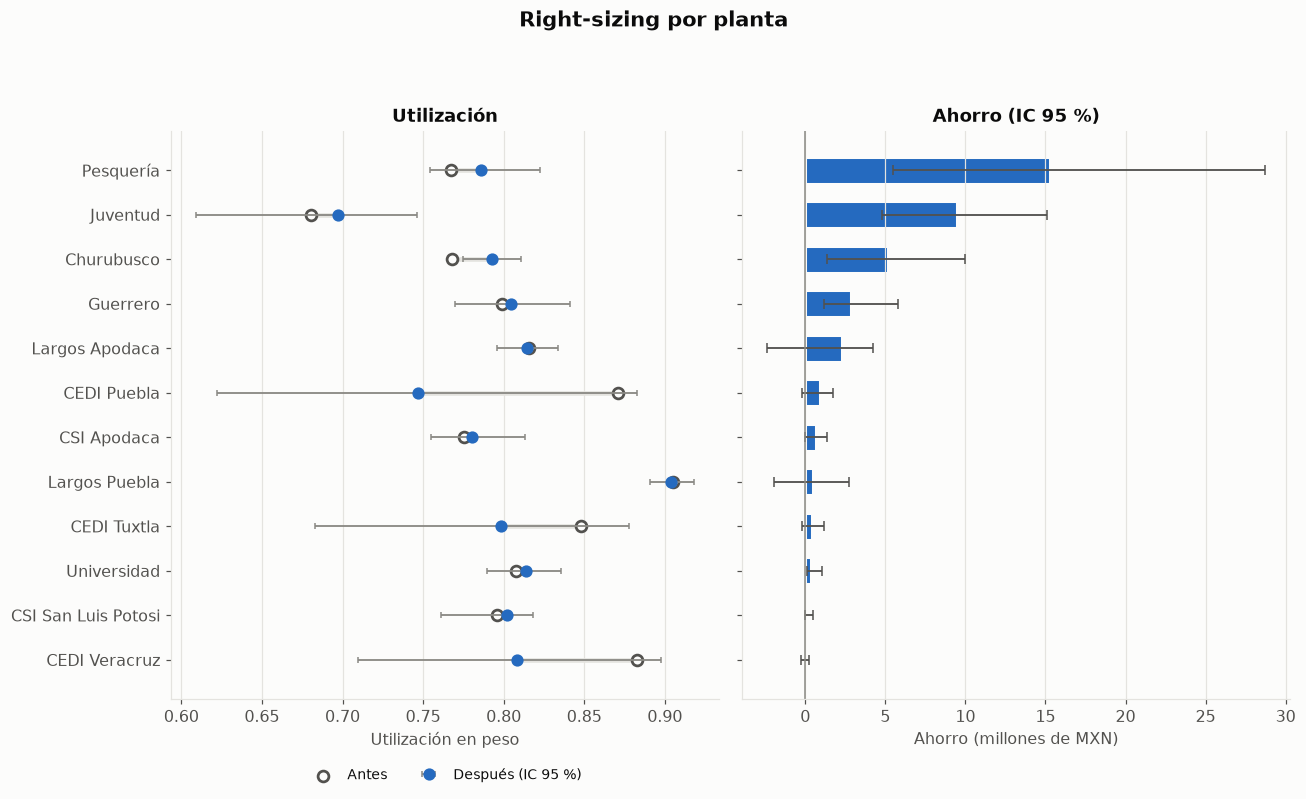

In [22]:
# FIG — Utilización antes y después, y ahorro, por planta (plantas con ≥ 30 viajes movidos)
d = rs_pl[rs_pl['Viajes movidos'] >= 30].sort_values('Ahorro_M', ascending=True)
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 0.45 * len(d) + 2), sharey=True)
y = np.arange(len(d))
ax1.hlines(y, d['u_antes'], d['u_despues'], color=REJILLA, lw=3)
ax1.scatter(d['u_antes'], y, s=50, facecolor=SUPERFICIE, edgecolor=TINTA_2, lw=1.8, zorder=3, label='Antes')
ax1.errorbar(d['u_despues'], y, xerr=[d['u_despues'] - d['u_despues_inf'], d['u_despues_sup'] - d['u_despues']],
             fmt='o', ms=7, color=SECUENCIAL[4], ecolor=TINTA_3, elinewidth=1.2, capsize=2, zorder=4,
             label='Después (IC 95 %)')
ax1.set_yticks(y, d.index); ax1.grid(axis='y', visible=False)
ax1.set_xlabel('Utilización en peso')
ax1.legend(loc='upper center', bbox_to_anchor=(0.5, -0.1), ncol=2, fontsize=9); ax1.set_title('Utilización')
ax2.barh(y, d['Ahorro_M'], color=SECUENCIAL[4], height=0.6, edgecolor=SUPERFICIE, linewidth=2)
ax2.errorbar(d['Ahorro_M'], y, xerr=[d['Ahorro_M'] - d['Ahorro_M_inf'], d['Ahorro_M_sup'] - d['Ahorro_M']],
             fmt='none', ecolor=TINTA_2, elinewidth=1.2, capsize=3)
ax2.axvline(0, color=TINTA_3, lw=1)
ax2.set_xlabel('Ahorro (millones de MXN)'); ax2.grid(axis='y', visible=False); ax2.set_title('Ahorro (IC 95 %)')
titulo(fig, 'Right-sizing por planta')
plt.show()